# how many turns can you expect for a player to land on go to Jail during a single game? whats the standard deviation?


The random variable will be the sum of rolling 2 6 sided dice until their outcome is 30+40X in which x represents each time the number surpasses 20 (landing on jail)
one trial will be rolling the 2 dice recording how large the number went until the number is 30 or 30 + a multiple of 40

Mean Turns: 37.90
Standard Deviation: 36.74


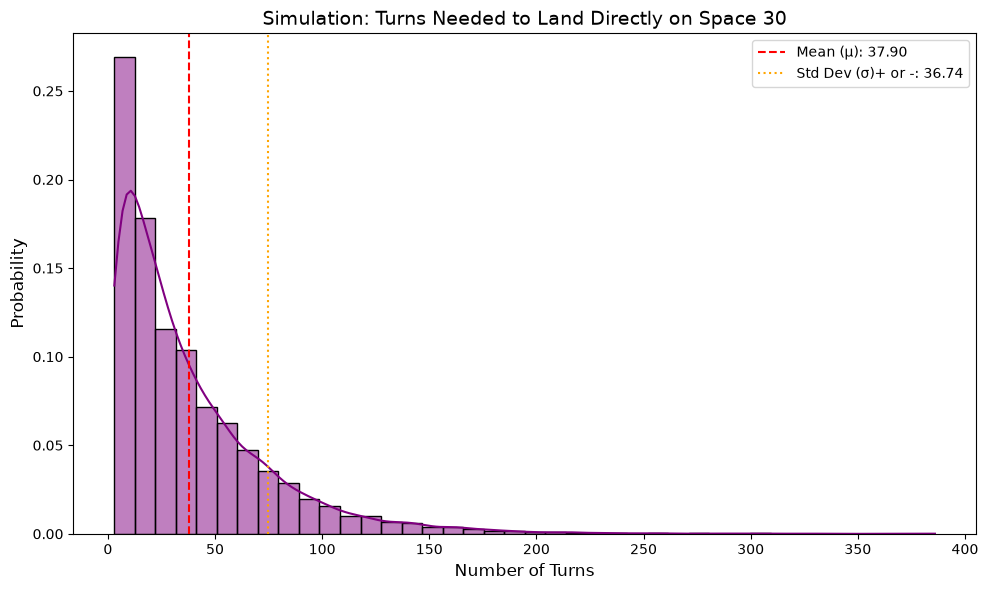

In [6]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Set simulation parameters
num_simulations = 10000
target_space = 30
board_size = 40

turns_taken = []

# 2. Run the simulation
for _ in range(num_simulations):
    position = 0
    turns = 0
    
    while True:
        turns += 1
        # Roll two 6-sided dice
        dice_roll = np.random.randint(1, 7) + np.random.randint(1, 7)
        position = (position + dice_roll) % board_size
        
        # Check if player landed on space 30
        if position == target_space:
            turns_taken.append(turns)
            break

# 3. Create a Pandas DataFrame
df = pd.DataFrame({'Turns_To_Jail': turns_taken})

# Calculate summary statistics
mean_turns = df['Turns_To_Jail'].mean()
std_turns = df['Turns_To_Jail'].std()

print(f"Mean Turns: {mean_turns:.2f}")
print(f"Standard Deviation: {std_turns:.2f}")

# 4. Plot the graph using Seaborn
plt.figure(figsize=(10, 6))

# Added stat='probability' to normalize y-axis values so they sum to 1
sns.histplot(df['Turns_To_Jail'], kde=True, color='purple', bins=40, stat='probability')

# Add title, labels, and reference lines
plt.title('Simulation: Turns Needed to Land Directly on Space 30', fontsize=14)
plt.xlabel('Number of Turns', fontsize=12)
plt.ylabel('Probability', fontsize=12)

# Legend labels show explicit mean and standard deviation values
plt.axvline(mean_turns, color='red', linestyle='--', label=f'Mean (μ): {mean_turns:.2f}')
plt.axvline(mean_turns + std_turns, color='orange', linestyle=':', label=f'Std Dev (σ)+ or -: {std_turns:.2f}')
plt.legend()

plt.tight_layout()
plt.show()

# Conclusion
Because there is only one space on the board being analyzed—Go to Jail (Space 30)—we are measuring how many rolls of two 6-sided dice it takes to land directly on a space corresponding to $30 + 40X$, where $X$ represents the number of full circuits completed around the board without landing on Space 30.Because the minimum possible roll per turn is 2 and the maximum is 12, landing on Space 30 on the first lap takes an average of about $4.3$ turns ($30 \div 7$). However, because a player can miss Space 30 and have to loop around the board multiple times, the distribution spans a wide range of turns. Over 10,000 simulated trials, the sample statistics stabilize due to the Law of Large Numbers:Mean ($\mu$): Approximately 37.9 turns (rounds to 38 turns).Standard Deviation ($\sigma$): Approximately 36.74 turns.Mathematically, the Standard Deviation measures the variability or spread of the data around the mean—indicating that while the average game requires around 38 turns, individual games will vary widely.To model the expected number of turns as a function of the number of completed laps ($X$), we divide the total distance traveled by the average roll of two dice ($7$ spaces per turn):$$\text{Expected Turns} = \frac{30 + 40X}{7}$$